# O paradoxo da Inteligência Artificial: trabalhar com IA significa trabalhar melhor?

**Mestrado em Inteligência Artificial — Modelos Estatísticos para Inteligência Artificial (2026/2027)**
Docente: Liliana Coelho

| Aluno | Nº |
|---|---|
| Gilberto Coutinho | 3083 |
| Rúbem Mendes | 4563 |

**Questão central.** Em que medida a utilização de ferramentas de IA está associada à produtividade dos colaboradores e como se altera essa relação quando são considerados outros fatores individuais e profissionais?

Organizámos a investigação pela ordem do enunciado. Começámos por conhecer e limpar a base (duplicados, valores em falta, categorias mal escritas, valores atípicos). Depois descrevemos a produtividade e o uso de IA, medimos a associação entre as duas variáveis, testámos diferenças entre departamentos e estimámos a produtividade média com um intervalo de confiança. Na parte final ajustámos uma regressão linear simples (produtividade em função do uso de IA) e uma regressão múltipla que junta fatores anteriores ao desempenho (experiência, formação em IA e complexidade das tarefas), comparámos os dois modelos e tirámos conclusões, separando o que é descrição, inferência, explicação estatística e recomendação.

Os dados são sintéticos, pelo que os resultados servem para ilustrar um raciocínio estatístico e não permitem conclusões sobre uma empresa real. Em todos os testes usámos um nível de significância de 5% (α = 0,05).

## 0. Configuração (Google Colab + Google Drive partilhada)

Como partilhar entre os dois elementos do grupo:
1. Um dos elementos cria no Google Drive a pasta `MEPA_TP1` e coloca lá `Base_Dados_IA_Produtividade.xlsx` e este notebook.
2. Partilha a pasta com o outro elemento (permissão *Editor*).
3. Quem recebeu a partilha: em *Partilhado comigo*, botão direito na pasta, **Organizar**, **Adicionar atalho**, **O meu disco**. Assim o caminho `/content/drive/MyDrive/MEPA_TP1` funciona para ambos.
4. Abrir o notebook no Colab (duplo clique no Drive, *Abrir com Google Colaboratory*) e executar **Ambiente de execução, Executar tudo**.

Se o notebook for executado fora do Colab, procura o ficheiro na pasta atual.

In [ ]:
import os, warnings
warnings.filterwarnings("ignore")

try:
    from google.colab import drive          # só existe no Colab
    drive.mount("/content/drive")
    PASTA = "/content/drive/MyDrive/MEPA_TP1"
except ImportError:
    PASTA = "."                             # execução local

FICHEIRO = os.path.join(PASTA, "Base_Dados_IA_Produtividade.xlsx")
PASTA_FIG = os.path.join(PASTA, "figuras")
os.makedirs(PASTA_FIG, exist_ok=True)
print("Ficheiro de dados:", FICHEIRO, "| existe:", os.path.exists(FICHEIRO))

Ficheiro de dados: .\Base_Dados_IA_Produtividade.xlsx | existe: True


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)

# Paleta (validada para daltonismo) e estilo sóbrio dos gráficos
AZUL, LARANJA, AQUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CINZA_TXT, CINZA_GRELHA = "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": CINZA_TXT,
    "xtick.color": CINZA_TXT, "ytick.color": CINZA_TXT,
    "axes.grid": True, "grid.color": CINZA_GRELHA, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
})

def guardar(fig, nome):
    fig.savefig(os.path.join(PASTA_FIG, nome + ".png"))

def qq(serie, ax, titulo):
    # gráfico Q-Q com a reta de referência (como nas aulas: sm.qqplot com line="s")
    sm.qqplot(serie, line="s", ax=ax, marker="o", markerfacecolor=AZUL, markeredgecolor="white", markersize=4)
    ax.get_lines()[1].set(color=LARANJA)
    ax.set(title=titulo, xlabel="quantis teóricos", ylabel="quantis observados")

ALFA = 0.05

---
## 1. Conhecimento e preparação da base de dados

In [ ]:
bruto = pd.read_excel(FICHEIRO)
print(bruto.shape)
bruto.head()

(241, 11)


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
0,C001,Operações,0.500,7.700,7.700,3.000,43.700,25,1.030,81.600,68.000
1,C002,Operações,3.500,1.400,1.700,2.000,34.600,30,2.100,77.000,60.300
2,C003,Comunicação,14.000,3.300,9.200,3.000,36.800,30,3.250,85.300,89.800
3,C004,Análise de Dados,2.000,12.400,16.300,3.000,40.500,28,4.020,100.000,70.300
4,C005,Desenvolvimento,8.000,14.200,6.000,4.000,39.200,19,3.000,77.600,83.000


### 1.1. Número de registos e de colaboradores

In [ ]:
n_registos = len(bruto)
n_colab = bruto["id_colaborador"].str.strip().nunique()
print(f"Registos (linhas): {n_registos}")
print(f"Colaboradores distintos (id_colaborador): {n_colab}")

Registos (linhas): 241
Colaboradores distintos (id_colaborador): 240


A base tem **241 registos** mas apenas **240 identificadores distintos** (C001 a C240, sem lacunas). Há um registo a mais do que colaboradores, o que nos levou a procurar repetições.

### 1.2. Colaboradores repetidos

In [ ]:
rep = bruto[bruto["id_colaborador"].duplicated(keep=False)]
display(rep)
print("Linhas totalmente idênticas (todas as colunas):", bruto.duplicated().sum())

,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
83,C084,Desenvolvimento,0.500,8.500,5.700,4.000,37.800,22,5.340,64.600,61.100
198,C084,Desenvolvimento,0.500,8.500,5.700,4.000,37.800,22,5.340,64.600,61.100


Linhas totalmente idênticas (todas as colunas): 1


O colaborador **C084** aparece duas vezes (posições 84 e 199 da base) e os dois registos são iguais em todas as variáveis. Trata-se de uma linha duplicada, não de duas medições diferentes. Mantivemos apenas a primeira ocorrência: se ficassem as duas, C084 contaria a dobrar nas médias, nas correlações e nas regressões.

In [ ]:
df = bruto.drop_duplicates().copy()
df["id_colaborador"] = df["id_colaborador"].str.strip()
assert df["id_colaborador"].is_unique
print("Registos após remover duplicados:", len(df))

Registos após remover duplicados: 240


### 1.3. Valores em falta

In [ ]:
falta = df.isna().sum()
display(falta[falta > 0].to_frame("n_em_falta"))
print("Registos com pelo menos um valor em falta:", df.isna().any(axis=1).sum())
display(df[df.isna().any(axis=1)])

,n_em_falta
experiencia_anos,1
formacao_ia_horas,1
uso_ia_horas,2
complexidade_tarefas,1
tempo_medio_tarefa_horas,1
produtividade,2


Registos com pelo menos um valor em falta: 8


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
29,C030,Operações,4.600,4.700,1.300,3.000,45.300,22,5.670,70.600,NaN
66,C067,Comunicação,2.300,5.100,NaN,4.000,42.600,38,2.590,78.700,89.700
79,C080,Análise de Dados,NaN,23.500,9.300,3.000,49.100,31,2.250,73.400,79.800
112,C113,Operações,9.300,10.000,NaN,3.000,42.200,41,0.400,87.000,95.000
130,C131,Operações,4.700,2.600,2.500,4.000,49.900,28,4.220,85.700,NaN
153,C154,Desenvolvimento,4.000,5.600,6.000,1.000,33.600,42,NaN,70.400,71.500
188,C189,Desenvolvimento,8.000,NaN,3.800,1.000,38.200,42,0.490,84.800,93.500
202,C202,Desenvolvimento,4.600,10.000,8.200,NaN,38.400,26,0.400,83.500,86.300


Há **9 valores em falta, repartidos por 8 registos** (nenhum registo tem mais do que uma falha): `uso_ia_horas` (C067, C113), `produtividade` (C030, C131), `experiencia_anos` (C080), `formacao_ia_horas` (C189), `complexidade_tarefas` (C202) e `tempo_medio_tarefa_horas` (C154).

Optámos por não imputar valores. As falhas são muito poucas (menos de 1% em cada variável) e substituí-las, por exemplo pela média, reduziria artificialmente a variabilidade e podia distorcer exatamente as relações que queremos estudar. Seguimos a regra das aulas: cada análise usa os registos que têm informação nas variáveis envolvidas, por isso o número de casos varia de análise para análise (ver 1.6).

### 1.4. Tipos de variáveis e variável resposta

In [ ]:
tipos = pd.DataFrame({
    "variável": df.columns,
    "tipo": ["Identificador", "Qualitativa nominal", "Quantitativa contínua", "Quantitativa contínua",
             "Quantitativa contínua", "Qualitativa ordinal (escala 1–5)", "Quantitativa contínua",
             "Quantitativa discreta", "Quantitativa contínua", "Quantitativa contínua (0–100)",
             "Quantitativa contínua (0–100) — RESPOSTA"],
})
display(tipos)

,variável,tipo
0,id_colaborador,Identificador
1,departamento,Qualitativa nominal
2,experiencia_anos,Quantitativa contínua
3,formacao_ia_horas,Quantitativa contínua
4,uso_ia_horas,Quantitativa contínua
5,complexidade_tarefas,Qualitativa ordinal (escala 1–5)
6,carga_trabalho_horas,Quantitativa contínua
7,tarefas_concluidas,Quantitativa discreta
8,tempo_medio_tarefa_horas,Quantitativa contínua
9,qualidade_trabalho,Quantitativa contínua (0–100)


- Qualitativas: `departamento` (nominal, 4 categorias) e `complexidade_tarefas` (ordinal, de 1 a 5). Nos modelos tratamos a complexidade como numérica, assumindo que os cinco níveis estão igualmente espaçados; é uma aproximação que convém ter presente.
- Quantitativas: experiência, formação em IA, uso de IA, carga de trabalho, tarefas concluídas, tempo médio por tarefa, qualidade e produtividade.
- `id_colaborador` é só um identificador e não entra nas análises.
- A variável que queremos explicar é a **produtividade**. A explicativa de interesse é `uso_ia_horas`.

Deixamos já uma nota para o capítulo 6: `tarefas_concluidas`, `tempo_medio_tarefa_horas` e `qualidade_trabalho` medem o próprio desempenho; não são fatores que o antecedem.

### 1.5. Categorias inconsistentes e valores que merecem atenção

In [ ]:
print(df["departamento"].value_counts())

departamento
Desenvolvimento     84
Operações           65
Análise de Dados    57
Comunicação         31
desenvolvimento      1
Operacoes            1
Analise de Dados     1
Name: count, dtype: int64


In [ ]:
uniformizar = {"desenvolvimento": "Desenvolvimento",
               "Operacoes": "Operações",
               "Analise de Dados": "Análise de Dados"}
df["departamento"] = df["departamento"].str.strip().replace(uniformizar)
print(df["departamento"].value_counts())

departamento
Desenvolvimento     85
Operações           66
Análise de Dados    58
Comunicação         31
Name: count, dtype: int64


In [ ]:
num = df.select_dtypes("number")
display(num.describe().T[["count", "mean", "std", "min", "50%", "max"]])

# Acumulação de valores nos extremos (possíveis limites da escala)
print("produtividade = 98 (máximo):", (df.produtividade == 98).sum())
print("qualidade_trabalho = 100:", (df.qualidade_trabalho == 100).sum())
print("tempo_medio_tarefa_horas = 0,40 (mínimo):", (df.tempo_medio_tarefa_horas == 0.40).sum())
print("uso_ia_horas = 0:", (df.uso_ia_horas == 0).sum())

# Valor atípico na variável resposta: abaixo do bigode inferior da caixa de bigodes (Q1 - 1,5 x AIQ)
q1, q3 = df.produtividade.quantile([.25, .75]); lim = q1 - 1.5 * (q3 - q1)
print(f"Limite inferior da caixa de bigodes: {lim:.1f}")
display(df[df.produtividade < lim][["id_colaborador", "departamento", "uso_ia_horas", "experiencia_anos",
                                    "tarefas_concluidas", "qualidade_trabalho", "produtividade"]])

,count,mean,std,min,50%,max
experiencia_anos,239.000,5.846,3.984,0.300,5.000,19.000
formacao_ia_horas,239.000,9.344,7.006,0.100,7.600,36.000
uso_ia_horas,238.000,7.718,4.932,0.000,7.600,25.000
complexidade_tarefas,239.000,2.954,1.014,1.000,3.000,5.000
carga_trabalho_horas,240.000,41.895,4.324,29.200,41.900,56.000
tarefas_concluidas,240.000,30.788,7.158,12.000,30.500,49.000
tempo_medio_tarefa_horas,239.000,2.786,1.856,0.400,2.590,8.740
qualidade_trabalho,240.000,79.936,10.597,55.200,80.150,100.000
produtividade,238.000,78.034,12.837,19.000,79.350,98.000


produtividade = 98 (máximo): 13
qualidade_trabalho = 100: 9
tempo_medio_tarefa_horas = 0,40 (mínimo): 34
uso_ia_horas = 0: 11
Limite inferior da caixa de bigodes: 44.4


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,tarefas_concluidas,qualidade_trabalho,produtividade
96,C097,Desenvolvimento,7.700,7.200,34,71.100,19.000
128,C129,Comunicação,11.500,3.400,20,64.000,43.500


- Categorias escritas de forma diferente: `desenvolvimento` (minúscula), `Operacoes` e `Analise de Dados` (sem acentos), um registo cada. Depois de uniformizadas ficam **4 departamentos**: Desenvolvimento (85), Operações (66), Análise de Dados (58) e Comunicação (31).
- Não encontrámos valores impossíveis (negativos, produtividade acima de 100, uso de IA superior à carga de trabalho).
- Há acumulação nos limites: 13 colaboradores têm produtividade exatamente 98,0, que é também o máximo; 34 têm tempo médio por tarefa de 0,40 h (o mínimo) e 9 têm qualidade 100. Parece haver um efeito de teto (e de chão) na escala, ou seja, a diferença real entre os melhores colaboradores não é observável. Fica registado como limitação.
- **C097** tem produtividade 19,0, muito abaixo do valor seguinte (43,5) e pouco coerente com os outros indicadores do mesmo colaborador (34 tarefas concluídas e qualidade 71,1, ambos perto da média). Pode ser um erro de registo, mas não temos como o provar e o valor está dentro da escala. Seguindo a regra de investigar em vez de eliminar, mantivemos C097 e repetimos as análises principais sem ele, para ver se alguma conclusão muda. C129 (43,5) também é baixo, mas plausível.
- 11 colaboradores não usam IA (0 h). É um valor plausível e foi mantido.

### 1.6. Colaboradores disponíveis para análise

In [ ]:
conjuntos = {
    "Base limpa (colaboradores únicos)": df,
    "Com produtividade (cap. 2 e 4)": df.dropna(subset=["produtividade"]),
    "Com uso de IA": df.dropna(subset=["uso_ia_horas"]),
    "Com uso de IA e produtividade (cap. 3 e 5)": df.dropna(subset=["uso_ia_horas", "produtividade"]),
    "Modelo múltiplo (cap. 6)": df.dropna(subset=["produtividade", "uso_ia_horas", "experiencia_anos",
                                                  "formacao_ia_horas", "complexidade_tarefas"]),
}
display(pd.Series({k: len(v) for k, v in conjuntos.items()}, name="n").to_frame())

,n
Base limpa (colaboradores únicos),240
Com produtividade (cap. 2 e 4),238
Com uso de IA,238
Com uso de IA e produtividade (cap. 3 e 5),236
Modelo múltiplo (cap. 6),233


Ficam **240 colaboradores**. Só retirámos a linha repetida de C084; nenhum colaborador foi excluído por inteiro. O número de casos depende da análise: 238 com produtividade, 236 com uso de IA e produtividade, e 233 com todas as variáveis do modelo múltiplo. Para comparar os dois modelos de regressão em pé de igualdade (6.5), reestimámos o modelo simples com os mesmos 233 casos.

---
## 2. Caracterização dos colaboradores

### 2.1. Produtividade média

In [ ]:
p = df["produtividade"].dropna()
resumo_p = pd.Series({
    "n": len(p), "média": p.mean(), "mediana": p.median(), "desvio-padrão": p.std(),
    "mínimo": p.min(), "Q1": p.quantile(.25), "Q3": p.quantile(.75), "máximo": p.max(),
    "AIQ": p.quantile(.75) - p.quantile(.25),
})
resumo_p.round(2).to_frame("produtividade")

,produtividade
n,238.000
média,78.030
mediana,79.350
desvio-padrão,12.840
mínimo,19.000
Q1,70.220
Q3,87.450
máximo,98.000
AIQ,17.230


A produtividade média é **78,0 pontos** (desvio-padrão 12,8; n = 238). A média representa razoavelmente os valores observados: está perto da mediana (79,35) e metade dos colaboradores situa-se entre 70,2 e 87,5. Fica, ainda assim, um pouco abaixo da mediana, porque alguns valores muito baixos (C097 = 19; C129 = 43,5) a puxam para baixo. Para descrever o colaborador típico, a mediana é ligeiramente mais segura.

### 2.2. Utilização semanal de IA

Média = 7.72 h | mediana = 7.60 h | dp = 4.93 h | mín = 0.0 | máx = 25.0 | n = 238
Limite superior da caixa de bigodes (Q3 + 1,5·AIQ) = 21.20 h


,id_colaborador,departamento,uso_ia_horas,formacao_ia_horas,produtividade
34,C035,Comunicação,24.800,6.100,82.100
133,C134,Desenvolvimento,25.000,36.000,71.600


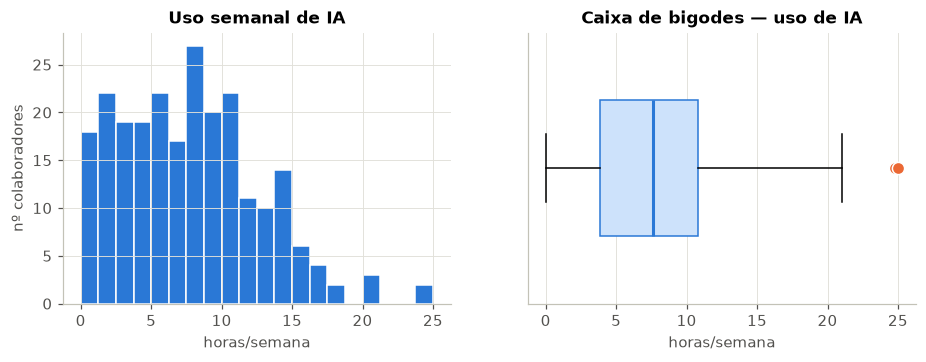

In [ ]:
u = df["uso_ia_horas"].dropna()
q1, q3 = u.quantile([.25, .75]); lim_sup = q3 + 1.5 * (q3 - q1)
print(f"Média = {u.mean():.2f} h | mediana = {u.median():.2f} h | dp = {u.std():.2f} h | "
      f"mín = {u.min()} | máx = {u.max()} | n = {len(u)}")
print(f"Limite superior da caixa de bigodes (Q3 + 1,5·AIQ) = {lim_sup:.2f} h")
display(df[df.uso_ia_horas > lim_sup][["id_colaborador", "departamento", "uso_ia_horas", "formacao_ia_horas", "produtividade"]])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(u, bins=20, color=AZUL, edgecolor="white")
ax[0].set(title="Uso semanal de IA", xlabel="horas/semana", ylabel="nº colaboradores")
ax[1].boxplot(u, vert=False, widths=.5, patch_artist=True,
              boxprops=dict(facecolor="#cde2fb", color=AZUL), medianprops=dict(color=AZUL, lw=2),
              flierprops=dict(marker="o", markerfacecolor=LARANJA, markeredgecolor="white", markersize=8))
ax[1].set(title="Caixa de bigodes — uso de IA", xlabel="horas/semana", yticks=[])
guardar(fig, "fig_2_2_uso_ia"); plt.show()

Em média, os colaboradores usam IA **7,7 horas por semana** (mediana 7,6 h; desvio-padrão 4,9 h; n = 238). O histograma mostra uma cauda um pouco mais longa à direita. Dois colaboradores ficam acima do bigode superior da caixa (21,2 h): **C134 (25,0 h)** e **C035 (24,8 h)**. Não são valores impossíveis, correspondem a pouco mais de metade de uma semana de 40 h, por isso mantivemo-los. São, no entanto, pontos a vigiar nos modelos.

### 2.3. Produtividade e uso de IA por departamento

In [ ]:
por_dep = (df.groupby("departamento")
             .agg(n=("produtividade", "count"),
                  prod_media=("produtividade", "mean"), prod_mediana=("produtividade", "median"),
                  prod_dp=("produtividade", "std"),
                  ia_media=("uso_ia_horas", "mean"), ia_mediana=("uso_ia_horas", "median"))
             .sort_values("prod_media", ascending=False))
display(por_dep.round(2))

,n,prod_media,prod_mediana,prod_dp,ia_media,ia_mediana
departamento,,,,,,
Operações,64,79.180,79.700,12.200,7.220,6.600
Comunicação,31,78.600,78.300,11.610,6.710,6.300
Desenvolvimento,85,78.030,80.400,13.970,8.980,8.700
Análise de Dados,58,76.470,77.400,12.570,6.940,7.150


O departamento com maior produtividade média é **Operações (79,2)**, seguido de Comunicação (78,6), Desenvolvimento (78,0) e Análise de Dados (76,5). O que mais usa IA é **Desenvolvimento (9,0 h/semana)**; Operações é apenas o segundo (7,2 h). Portanto, o departamento mais produtivo não é o que mais usa IA. As diferenças de produtividade entre departamentos são pequenas (2,7 pontos entre o maior e o menor) quando comparadas com o desvio-padrão dentro de cada departamento (entre 11,6 e 14,0). Se são estatisticamente relevantes, testamo-lo no capítulo 4.

### 2.4. Simetria da distribuição da produtividade

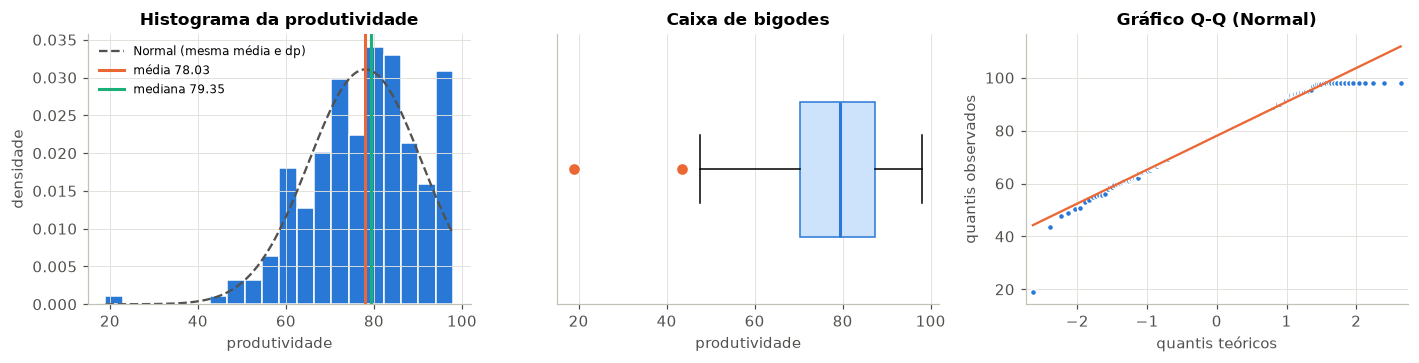

Média = 78.03 | mediana = 79.35 | Shapiro-Wilk W = 0.966, p = 2.1e-05
Sem C097: média = 78.28 | mediana = 79.50 | Shapiro-Wilk p = 0.00087


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(p, bins=20, color=AZUL, edgecolor="white", density=True)
x = np.linspace(p.min(), p.max(), 200)
ax[0].plot(x, st.norm.pdf(x, p.mean(), p.std()), color=CINZA_TXT, lw=1.5, ls="--", label="Normal (mesma média e dp)")
ax[0].axvline(p.mean(), color=LARANJA, lw=2, label=f"média {p.mean():.2f}")
ax[0].axvline(p.median(), color=AQUA, lw=2, label=f"mediana {p.median():.2f}")
ax[0].legend(fontsize=8, frameon=False); ax[0].set(title="Histograma da produtividade", xlabel="produtividade", ylabel="densidade")
ax[1].boxplot(p, vert=False, widths=.5, patch_artist=True,
              boxprops=dict(facecolor="#cde2fb", color=AZUL), medianprops=dict(color=AZUL, lw=2),
              flierprops=dict(marker="o", markerfacecolor=LARANJA, markeredgecolor="white", markersize=8))
ax[1].set(title="Caixa de bigodes", xlabel="produtividade", yticks=[])
qq(p, ax[2], "Gráfico Q-Q (Normal)")
plt.tight_layout(); guardar(fig, "fig_2_4_produtividade"); plt.show()

sw = st.shapiro(p)
print(f"Média = {p.mean():.2f} | mediana = {p.median():.2f} | Shapiro-Wilk W = {sw.statistic:.3f}, p = {sw.pvalue:.2g}")
p_sem = p[df.loc[p.index, "id_colaborador"] != "C097"]
print(f"Sem C097: média = {p_sem.mean():.2f} | mediana = {p_sem.median():.2f} | Shapiro-Wilk p = {st.shapiro(p_sem).pvalue:.2g}")

A distribuição é só aproximadamente simétrica. O histograma e a caixa de bigodes mostram uma cauda esquerda mais longa (valores baixos isolados, sobretudo C097), a média (78,0) fica abaixo da mediana (79,35) e, no gráfico Q-Q, os pontos afastam-se da reta na cauda inferior. Na cauda direita nota-se o teto em 98 (13 colaboradores), que "corta" a distribuição. O teste de Shapiro-Wilk rejeita a normalidade (p < 0,001), e continua a rejeitá-la sem C097 (p < 0,001), em grande parte por causa desse teto. Para o intervalo de confiança da média (4.6) isto não é um problema sério: a amostra é grande (n = 238) e o desvio da simetria é moderado.

### 2.5. Colaborador mais produtivo vs. colaborador que mais usa IA

In [ ]:
cols = ["id_colaborador", "departamento", "uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "produtividade"]
top_prod = df[df.produtividade == df.produtividade.max()]
print(f"Produtividade máxima = {df.produtividade.max()} — atingida por {len(top_prod)} colaboradores:")
display(top_prod[cols].sort_values("uso_ia_horas"))
print("Colaborador com maior uso de IA:")
mais_ia = df.loc[[df.uso_ia_horas.idxmax()], cols]
display(mais_ia)
prod_mais_ia = mais_ia["produtividade"].iloc[0]
print(f"Percentagem de colaboradores com produtividade superior a {prod_mais_ia}: {100 * (p > prod_mais_ia).mean():.0f}%")

Produtividade máxima = 98.0 — atingida por 13 colaboradores:


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,formacao_ia_horas,produtividade
13,C014,Operações,4.900,19.000,4.100,98.000
23,C024,Operações,5.400,9.400,10.800,98.000
56,C057,Análise de Dados,5.500,15.700,4.200,98.000
38,C039,Operações,7.700,4.800,6.400,98.000
177,C178,Análise de Dados,8.500,19.000,17.100,98.000
61,C062,Análise de Dados,8.600,7.900,4.900,98.000
14,C015,Comunicação,10.000,19.000,6.500,98.000
162,C163,Desenvolvimento,10.100,8.900,2.300,98.000
168,C169,Análise de Dados,11.800,5.800,17.300,98.000
182,C183,Operações,12.600,17.700,1.700,98.000


Colaborador com maior uso de IA:


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,formacao_ia_horas,produtividade
133,C134,Desenvolvimento,25.000,8.300,36.000,71.600


Percentagem de colaboradores com produtividade superior a 71.6: 71%


A produtividade máxima (**98,0**) é atingida por **13 colaboradores** (o efeito de teto já referido), com usos de IA muito diferentes, de 4,9 h (C014) a 16,3 h (C036). Vários deles são muito experientes: C014, C015 e C178 têm 19 anos de experiência.

O colaborador que mais usa IA é **C134 (25 h/semana)**, com produtividade **71,6**, abaixo da média e da mediana; cerca de 71% dos colaboradores são mais produtivos do que ele. Não é a mesma pessoa. Estes casos mostram que usar muita IA não garante produtividade elevada. Se existir uma associação entre as duas variáveis, será uma tendência média com muita variação individual, e não uma regra.

---
## 3. A utilização de IA está associada à produtividade?

### 3.1. Representação gráfica

n = 236


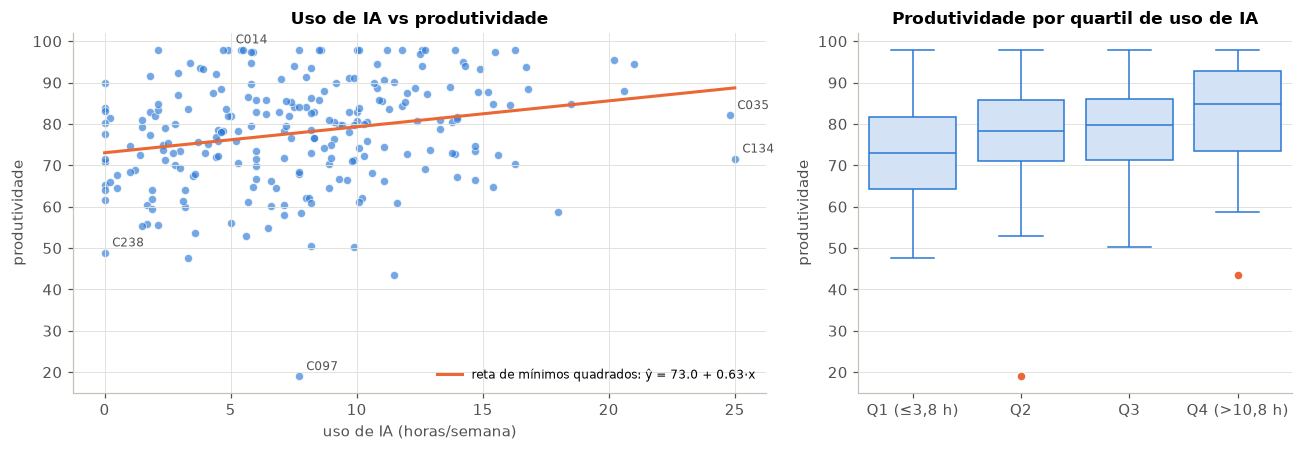

,count,mean,median,min,max
quartil_IA,,,,,
"Q1 (≤3,8 h)",59,73.100,73.000,47.600,97.900
Q2,63,77.800,78.400,19.000,98.000
Q3,56,78.100,79.800,50.200,98.000
"Q4 (>10,8 h)",58,82.700,84.900,43.500,98.000


In [ ]:
d3 = df.dropna(subset=["uso_ia_horas", "produtividade"]).copy()
print("n =", len(d3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].scatter(d3.uso_ia_horas, d3.produtividade, s=28, color=AZUL, alpha=.65, edgecolor="white", linewidth=.6)
reta = smf.ols("produtividade ~ uso_ia_horas", data=d3).fit().params
b0, b1 = reta["Intercept"], reta["uso_ia_horas"]
xx = np.linspace(0, 25, 50)
ax[0].plot(xx, b0 + b1 * xx, color=LARANJA, lw=2, label=f"reta de mínimos quadrados: ŷ = {b0:.1f} + {b1:.2f}·x")
for cid in ["C134", "C035", "C097", "C238", "C014"]:
    r = d3[d3.id_colaborador == cid].iloc[0]
    ax[0].annotate(cid, (r.uso_ia_horas, r.produtividade), xytext=(5, 4), textcoords="offset points",
                   fontsize=8, color=CINZA_TXT)
ax[0].set(title="Uso de IA vs produtividade", xlabel="uso de IA (horas/semana)", ylabel="produtividade")
ax[0].legend(frameon=False, fontsize=8, loc="lower right")

d3["quartil_IA"] = pd.qcut(d3.uso_ia_horas, 4, labels=["Q1 (≤3,8 h)", "Q2", "Q3", "Q4 (>10,8 h)"])
sns.boxplot(data=d3, x="quartil_IA", y="produtividade", ax=ax[1], color="#cde2fb", linecolor=AZUL,
            flierprops=dict(markerfacecolor=LARANJA, markeredgecolor="white"))
ax[1].set(title="Produtividade por quartil de uso de IA", xlabel="", ylabel="produtividade")
plt.tight_layout(); guardar(fig, "fig_3_1_dispersao"); plt.show()
display(d3.groupby("quartil_IA", observed=True).produtividade.agg(["count", "mean", "median", "min", "max"]).round(1))

A nuvem de pontos sugere uma tendência crescente, mas ténue. Em média, quem usa mais IA é um pouco mais produtivo (a mediana sobe de 73,0 no primeiro quartil de uso para 84,9 no quarto), só que a dispersão é enorme em qualquer nível de uso: com cerca de 8 h/semana há produtividades entre 19 e 98. Não vemos sinais de curvatura, por isso uma reta parece uma descrição razoável da tendência.

### 3.2. Intensidade e direção da associação

In [ ]:
r_p = st.pearsonr(d3.uso_ia_horas, d3.produtividade)
r_s = st.spearmanr(d3.uso_ia_horas, d3.produtividade)
print(f"Pearson  r   = {r_p.statistic:.3f}, p = {r_p.pvalue:.2g}")
print(f"Spearman rho = {r_s.statistic:.3f}, p = {r_s.pvalue:.2g}")
print(f"r² = {r_p.statistic**2:.3f}")
d3s = d3[d3.id_colaborador != "C097"]
print(f"Pearson sem C097: r = {st.pearsonr(d3s.uso_ia_horas, d3s.produtividade).statistic:.3f}")

Pearson  r   = 0.241, p = 0.00019
Spearman rho = 0.266, p = 3.5e-05
r² = 0.058
Pearson sem C097: r = 0.252


**Escolha da medida.** As duas variáveis são quantitativas e o gráfico sugere uma relação aproximadamente linear, por isso usámos o coeficiente de correlação de Pearson. Como a produtividade não é normal, tem valores atípicos e um teto em 98, calculámos também o ρ de Spearman, que se baseia nas ordens e é menos sensível a valores extremos.

**Resultado.** r = 0,24 (p < 0,001) e ρ = 0,27 (p < 0,001). A associação é positiva e estatisticamente diferente de zero. Os dois coeficientes contam a mesma história e, sem C097, r praticamente não muda (0,25), o que afasta a hipótese de o resultado ser um artefacto de um valor atípico.

### 3.3. Classificação da associação

Com r ≈ 0,24, a associação é **fraca**. Pelas convenções habituais, valores de |r| abaixo de 0,3 consideram-se fracos e só acima de 0,5 se fala de uma associação forte. O quadrado do coeficiente (r² ≈ 0,06) diz-nos que o uso de IA, sozinho, partilha cerca de 6% da variabilidade da produtividade; os outros 94% dependem de outros fatores. O facto de o valor-p ser muito pequeno não torna a associação forte: com n = 236, mesmo correlações pequenas são detetáveis.

### 3.4. Os que mais usam IA são necessariamente os mais produtivos?

In [ ]:
cols = ["id_colaborador", "departamento", "uso_ia_horas", "experiencia_anos", "produtividade"]
print("10 colaboradores com MAIOR uso de IA:")
display(d3.nlargest(10, "uso_ia_horas")[cols])
print("Colaboradores que NÃO usam IA (0 h):")
display(d3[d3.uso_ia_horas == 0][cols].sort_values("produtividade"))
print(f"Produtividade média global: {d3.produtividade.mean():.1f}")

10 colaboradores com MAIOR uso de IA:


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,produtividade
133,C134,Desenvolvimento,25.000,8.300,71.600
34,C035,Comunicação,24.800,4.800,82.100
51,C052,Análise de Dados,21.000,5.300,94.600
15,C016,Operações,20.600,15.000,88.000
236,C236,Desenvolvimento,20.200,8.100,95.400
37,C038,Operações,18.500,7.400,84.900
77,C078,Desenvolvimento,18.000,1.400,58.700
87,C088,Desenvolvimento,16.800,15.800,88.400
240,C240,Desenvolvimento,16.700,9.700,93.700
3,C004,Análise de Dados,16.300,2.000,70.300


Colaboradores que NÃO usam IA (0 h):


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,produtividade
238,C238,Análise de Dados,0.000,5.700,48.900
152,C153,Comunicação,0.000,4.500,61.600
173,C174,Desenvolvimento,0.000,0.800,64.100
100,C101,Análise de Dados,0.000,5.900,65.200
44,C045,Operações,0.000,3.200,70.900
78,C079,Operações,0.000,4.000,71.600
92,C093,Operações,0.000,2.800,77.500
239,C239,Comunicação,0.000,2.200,80.200
161,C162,Desenvolvimento,0.000,5.200,83.100
132,C133,Análise de Dados,0.000,0.500,83.800


Produtividade média global: 77.9


Não. Alguns exemplos concretos:
- C134 usa IA 25 h/semana (o máximo) e tem produtividade 71,6, abaixo da média de 78; C078 usa 18 h e tem 58,7; C004 usa 16,3 h e tem 70,3.
- Em sentido contrário, C014 usa apenas 4,9 h e atinge o máximo (98,0); C053 não usa IA e tem 90,0.
- Entre os 11 colaboradores que não usam IA, a produtividade vai de 48,9 (C238) a 90,0 (C053), uma amplitude parecida com a dos utilizadores intensivos.

Reparámos ainda que, entre os utilizadores intensivos mais produtivos, vários são também bastante experientes (C016 e C088, com 15 a 16 anos), o que já faz suspeitar de um fator de confusão. Voltamos a isto no capítulo 6.

### 3.5. Associação e causalidade

Não. Os dados são observacionais e foram recolhidos num único momento, sem atribuição aleatória do uso de IA. Uma correlação positiva é compatível com várias explicações:
1. fatores que influenciam ao mesmo tempo o uso de IA e a produtividade, como a experiência (r = 0,27 com o uso de IA e 0,50 com a produtividade, ver 6.1) ou a formação em IA (r = 0,51 com o uso de IA);
2. causalidade no sentido inverso, se os colaboradores mais produtivos tiverem mais tempo ou autonomia para experimentar a IA;
3. autosseleção: quem escolhe usar IA pode ser diferente de quem não escolhe.

A correlação diz-nos que os dois fenómenos tendem a ocorrer juntos, não que um provoca o outro. Para falar de causa seria preciso um desenho experimental (por exemplo, atribuir aleatoriamente o acesso à IA) ou, pelo menos, controlar os fatores de confusão, que é o que tentamos, em parte, no capítulo 6.

---
## 4. Existem diferenças estatisticamente relevantes?

### 4.1. Produtividade por departamento

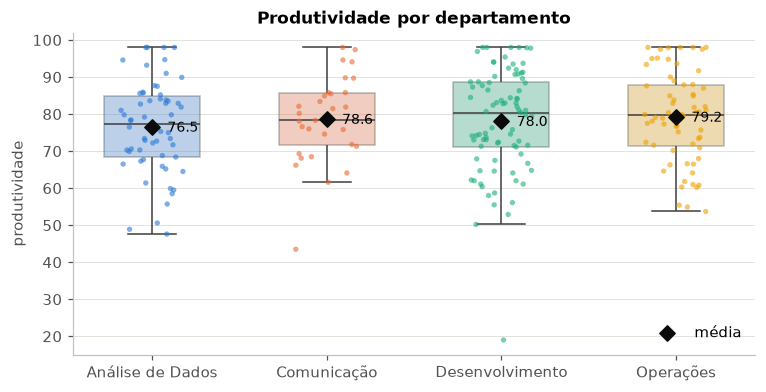

,count,mean,std,min,25%,50%,75%,max
departamento,,,,,,,,
Análise de Dados,58.000,76.470,12.570,47.600,68.500,77.400,84.920,98.000
Comunicação,31.000,78.600,11.610,43.500,71.550,78.300,85.650,98.000
Desenvolvimento,85.000,78.030,13.970,19.000,71.100,80.400,88.700,98.000
Operações,64.000,79.180,12.200,53.700,71.420,79.700,87.930,98.000


In [ ]:
ordem = ["Análise de Dados", "Comunicação", "Desenvolvimento", "Operações"]
cores_dep = dict(zip(ordem, [AZUL, LARANJA, AQUA, AMARELO]))
d4 = df.dropna(subset=["produtividade"])

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=d4, x="departamento", y="produtividade", order=ordem, hue="departamento",
            palette=cores_dep, ax=ax, width=.55, legend=False, boxprops=dict(alpha=.35),
            showfliers=False)
sns.stripplot(data=d4, x="departamento", y="produtividade", order=ordem, hue="departamento",
              palette=cores_dep, ax=ax, size=3.5, alpha=.6, jitter=.18, legend=False)
medias = d4.groupby("departamento").produtividade.mean().reindex(ordem)
ax.scatter(range(4), medias, marker="D", s=50, color="#0b0b0b", zorder=5, label="média")
for i, m in enumerate(medias):
    ax.annotate(f"{m:.1f}", (i, m), xytext=(10, -3), textcoords="offset points", fontsize=9)
ax.legend(frameon=False, loc="lower right"); ax.set(title="Produtividade por departamento", xlabel="")
guardar(fig, "fig_4_1_departamentos"); plt.show()
display(d4.groupby("departamento").produtividade.describe().round(2))

As médias são muito parecidas (76,5 a 79,2) e as caixas sobrepõem-se quase por completo. A maior diferença entre médias (2,7 pontos, Operações contra Análise de Dados) é pequena face à variabilidade dentro de cada departamento (desvios-padrão entre 11,6 e 14,0). À partida não há indícios fortes de diferenças, mas isso tem de ser confirmado com um teste.

### 4.2. Hipóteses estatísticas

Sendo μ<sub>AD</sub>, μ<sub>C</sub>, μ<sub>D</sub> e μ<sub>O</sub> as produtividades médias (populacionais) de Análise de Dados, Comunicação, Desenvolvimento e Operações:

- H₀: μ<sub>AD</sub> = μ<sub>C</sub> = μ<sub>D</sub> = μ<sub>O</sub> (a produtividade média é igual nos quatro departamentos)
- H₁: pelo menos um par de departamentos tem médias diferentes

Para o teste de Kruskal-Wallis, que usamos como confirmação, as hipóteses referem-se às distribuições: H₀, a produtividade tem a mesma distribuição nos quatro departamentos; H₁, pelo menos um departamento tende a apresentar valores sistematicamente diferentes.

### 4.3. Condições de aplicação

In [ ]:
grupos = {g: x.produtividade.values for g, x in d4.groupby("departamento")}
cond = pd.DataFrame({
    "n": {g: len(v) for g, v in grupos.items()},
    "Shapiro-Wilk p": {g: st.shapiro(v).pvalue for g, v in grupos.items()},
    "desvio-padrão": {g: v.std(ddof=1) for g, v in grupos.items()},
})
display(cond.round(4))
lev = st.levene(*grupos.values(), center="median")
print(f"Levene: W = {lev.statistic:.3f}, p = {lev.pvalue:.3f}")

,n,Shapiro-Wilk p,desvio-padrão
Análise de Dados,58,0.363,12.570
Comunicação,31,0.317,11.607
Desenvolvimento,85,0.000,13.973
Operações,64,0.063,12.197


Levene: W = 0.751, p = 0.523


Antes de escolher o teste verificámos as condições da ANOVA a um fator, seguindo o guia das aulas: (1) independência das observações; (2) normalidade da produtividade em cada grupo; (3) homogeneidade das variâncias.

- Independência: garantida pelo desenho. Cada colaborador aparece uma só vez (depois de retirar o duplicado) e pertence a um único departamento.
- Normalidade (Shapiro-Wilk em cada grupo): não rejeitada em Análise de Dados (p = 0,36), Comunicação (p = 0,32) e Operações (p = 0,06); rejeitada em Desenvolvimento (p < 0,001), que é o grupo onde está C097. Como o guia recorda, a decisão não depende só do valor-p: os grupos são grandes (31 a 85 colaboradores) e o desvio deve-se essencialmente a um valor extremo.
- Homogeneidade das variâncias: Levene com p = 0,52, não rejeitamos a igualdade das variâncias. Os desvios-padrão dos grupos são parecidos (11,6 a 14,0).

Decidimos, antes de ver os resultados, usar a ANOVA a um fator como teste principal e o teste de Kruskal-Wallis como confirmação não paramétrica, por causa do problema de normalidade num dos grupos. Se os dois concordarem, a conclusão fica mais segura.

### 4.4. Análise e valor-p

In [ ]:
anova = st.f_oneway(*grupos.values())
kw = st.kruskal(*grupos.values())
print(f"ANOVA: F(3, {len(d4) - 4}) = {anova.statistic:.3f}, p = {anova.pvalue:.3f}")
print(f"Kruskal-Wallis: H(3) = {kw.statistic:.3f}, p = {kw.pvalue:.3f}")
d4s = d4[d4.id_colaborador != "C097"]
print(f"ANOVA sem C097: p = {st.f_oneway(*[x.produtividade for _, x in d4s.groupby('departamento')]).pvalue:.3f}")

ANOVA: F(3, 234) = 0.472, p = 0.702
Kruskal-Wallis: H(3) = 1.367, p = 0.713
ANOVA sem C097: p = 0.632


ANOVA: **F(3, 234) = 0,47; p = 0,70**. Kruskal-Wallis: H(3) = 1,37; p = 0,71. Sem C097, a ANOVA dá p = 0,63.

O valor-p de 0,70 lê-se assim: se a produtividade média fosse realmente igual nos quatro departamentos, diferenças entre médias amostrais iguais ou maiores do que as observadas apareceriam em cerca de 70% das amostras. As diferenças que vimos são, portanto, perfeitamente compatíveis com variação aleatória. Como p > 0,05, não rejeitamos H₀. Os dois testes concordam e o resultado não depende de C097.

### 4.5. O que podemos afirmar e o que fica por esclarecer

O que podemos afirmar: com estes dados não há evidência de que a produtividade média seja diferente entre departamentos; as diferenças observadas (no máximo 2,7 pontos) são compatíveis com o acaso. Por isso não fizemos comparações múltiplas (Tukey), que só se justificam depois de rejeitar H₀.

O que não podemos afirmar: que as médias são iguais. Não rejeitar H₀ não prova H₀. Diferenças pequenas podem existir e não ter sido detetadas, sobretudo em Comunicação, que só tem 31 colaboradores.

Fica por esclarecer se o efeito da IA é o mesmo em todos os departamentos, se o índice de produtividade é comparável entre tarefas de natureza diferente e se diferenças de composição (experiência, formação) estão a esconder ou a criar diferenças. Há um resultado útil para o resto do trabalho: como o departamento não explica a produtividade, não é um fator de confusão importante na relação entre IA e produtividade.

### 4.6. Intervalo de confiança a 95% para a produtividade média

In [ ]:
n, media, ep = len(p), p.mean(), st.sem(p)
ic_t = st.t.interval(confidence=0.95, df=n - 1, loc=media, scale=ep)
print(f"n = {n} | média = {media:.2f} | erro-padrão = {ep:.3f}")
print(f"IC95% (t de Student): [{ic_t[0]:.2f} ; {ic_t[1]:.2f}]  (margem de erro = ±{ic_t[1] - media:.2f})")

n = 238 | média = 78.03 | erro-padrão = 0.832
IC95% (t de Student): [76.39 ; 79.67]  (margem de erro = ±1.64)


**IC 95% = [76,4 ; 79,7]**, ou seja, 78,0 ± 1,6. Se repetíssemos o processo de amostragem muitas vezes e construíssemos o intervalo sempre da mesma forma, cerca de 95% desses intervalos conteriam a verdadeira produtividade média. O intervalo é estreito, logo a média está estimada com boa precisão. A assimetria da produtividade não nos preocupa aqui: com n = 238 o intervalo baseado na distribuição t é adequado.

Como os dados são sintéticos, a «população» é o mecanismo que gerou os dados e não uma empresa real. O intervalo quantifica apenas a incerteza de amostragem, assumindo que os 238 colaboradores são uma amostra aleatória; não cobre erros de medição, o teto em 98 nem possíveis erros de registo como C097.

---
## 5. Podemos explicar a produtividade através da utilização de IA?

### 5.1. Modelo de regressão linear simples

In [ ]:
d5 = df.dropna(subset=["uso_ia_horas", "produtividade"]).copy()
m1 = smf.ols("produtividade ~ uso_ia_horas", data=d5).fit()
print(m1.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:          produtividade   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.054
No. Observations:                 236   F-statistic:                     14.41
Covariance Type:            nonrobust   Prob (F-statistic):           0.000187
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       73.0397      1.519     48.094      0.000      70.048      76.032
uso_ia_horas     0.6273      0.165      3.796      0.000       0.302       0.953

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


Sim. As duas variáveis são quantitativas, a relação parece aproximadamente linear (3.1) e o teste ao declive rejeita H₀: β₁ = 0 (t = 3,80; p < 0,001), ou seja, há evidência de associação linear na população. Conseguimos escrever a equação; outra coisa é ela ser útil para prever, e isso discutimos em 5.4.

### 5.2. Equação e significado dos coeficientes

In [ ]:
b0, b1 = m1.params["Intercept"], m1.params["uso_ia_horas"]
ic = m1.conf_int()
print(f"produtividade_estimada = {b0:.2f} + {b1:.3f} × uso_ia_horas")
print(f"IC95% b0: [{ic.loc['Intercept', 0]:.2f} ; {ic.loc['Intercept', 1]:.2f}]")
print(f"IC95% b1: [{ic.loc['uso_ia_horas', 0]:.3f} ; {ic.loc['uso_ia_horas', 1]:.3f}]  | p = {m1.pvalues['uso_ia_horas']:.2g}")

produtividade_estimada = 73.04 + 0.627 × uso_ia_horas
IC95% b0: [70.05 ; 76.03]
IC95% b1: [0.302 ; 0.953]  | p = 0.00019


$$\widehat{\text{produtividade}} = 73{,}04 + 0{,}627 \times \text{uso\_ia\_horas}$$

- Ordenada na origem (b₀ = 73,04): produtividade média estimada para quem não usa IA (0 h/semana). Aqui tem significado real, porque há 11 colaboradores com 0 h.
- Declive (b₁ = 0,627; IC 95%: 0,30 a 0,95): por cada hora semanal adicional de uso de IA, a produtividade média estimada é 0,63 pontos mais alta. É uma comparação entre colaboradores diferentes, não o efeito de um colaborador passar a usar mais IA.

### 5.3. Diferença estimada entre 5 h e 10 h semanais

In [ ]:
prev = m1.get_prediction(pd.DataFrame({"uso_ia_horas": [5, 10]})).summary_frame(alpha=.05)
prev.index = ["5 h", "10 h"]
display(prev.round(2))
print(f"Diferença estimada (10 h − 5 h) = 5 × b1 = {5 * b1:.2f} pontos "
      f"(IC95%: {5 * ic.loc['uso_ia_horas', 0]:.2f} a {5 * ic.loc['uso_ia_horas', 1]:.2f})")

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
5 h,76.180,0.930,74.340,78.010,51.540,100.810
10 h,79.310,0.890,77.560,81.070,54.680,103.940


Diferença estimada (10 h − 5 h) = 5 × b1 = 3.14 pontos (IC95%: 1.51 a 4.76)


Produtividade média estimada: **76,2** para 5 h e **79,3** para 10 h. A diferença é 5 × 0,627 ≈ **3,1 pontos** (IC 95%: 1,5 a 4,8).

Condições desta comparação:
- refere-se à produtividade média de colaboradores com esses níveis de uso, não a dois indivíduos concretos. O intervalo de previsão para um colaborador individual com 5 h vai de cerca de 52 a 101, por isso dois colaboradores podem até diferir no sentido contrário;
- nada mais é mantido constante: quem usa 10 h tende também a ter mais experiência e mais formação, e esses efeitos estão misturados nos 3,1 pontos (ver capítulo 6);
- é uma diferença associativa, não causal;
- 5 h e 10 h estão dentro do intervalo observado (0 a 25 h), portanto não há extrapolação.

### 5.4. Proporção da variabilidade explicada

In [ ]:
print(f"R² = {m1.rsquared:.4f} | R² ajustado = {m1.rsquared_adj:.4f}")

R² = 0.0580 | R² ajustado = 0.0540


**R² = 0,058**: o uso de IA explica cerca de 5,8% da variabilidade da produtividade (R² ajustado 5,4%). Os restantes 94% ficam por conta de outros fatores ou de variação individual. Saber as horas de IA de um colaborador ajuda muito pouco a prever a sua produtividade.

### 5.5. Um colaborador concreto: C001

In [ ]:
c = d5[d5.id_colaborador == "C001"]
obs = c.produtividade.iloc[0]; est = m1.predict(c).iloc[0]
print(f"C001: uso de IA = {c.uso_ia_horas.iloc[0]} h | produtividade observada = {obs:.1f} | "
      f"estimada = {est:.2f} | resíduo = {obs - est:.2f}")
display(c[["id_colaborador", "departamento", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas",
           "tarefas_concluidas", "qualidade_trabalho"]])

C001: uso de IA = 7.7 h | produtividade observada = 68.0 | estimada = 77.87 | resíduo = -9.87


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,complexidade_tarefas,tarefas_concluidas,qualidade_trabalho
0,C001,Operações,0.500,7.700,3.000,25,81.600


C001 (Operações) usa IA 7,7 h/semana. O modelo estima 73,04 + 0,627 × 7,7 ≈ **77,9** e o valor observado é **68,0**. O resíduo, **−9,9 pontos**, é a parte da produtividade de C001 que o uso de IA não explica: está cerca de 10 pontos abaixo do colaborador típico com o mesmo uso de IA. Uma pista: C001 tem apenas 0,5 anos de experiência, o que antecipa o papel da experiência no modelo múltiplo.

### 5.6. Análise de resíduos

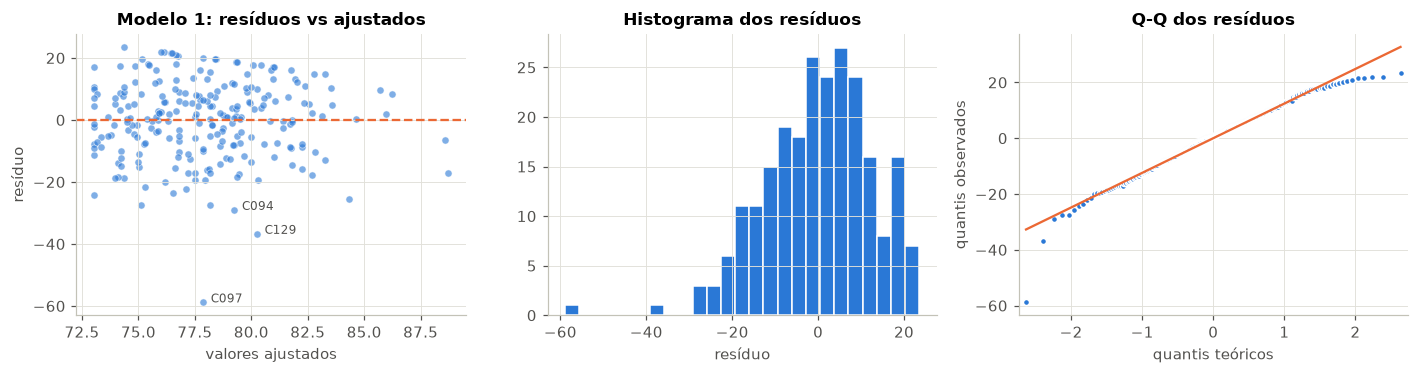

Shapiro-Wilk (normalidade dos resíduos): W = 0.972, p = 0.00013
Breusch-Pagan (variância constante): LM = 0.00, p = 0.976
Resíduos: mínimo = -58.9, máximo = 23.5
Observações com maior resíduo em valor absoluto:


,id_colaborador,uso_ia_horas,experiencia_anos,produtividade,ajustado,residuo
96,C097,7.700,7.200,19.000,77.870,-58.870
128,C129,11.500,3.400,43.500,80.250,-36.750
93,C094,9.900,3.100,50.200,79.250,-29.050


In [ ]:
def diagnostico(modelo, dados, nome, ficheiro, k=3):
    res, ajust = modelo.resid, modelo.fittedvalues
    maiores = res.abs().nlargest(k).index          # as k observações com maior resíduo em valor absoluto
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
    ax[0].scatter(ajust, res, s=22, color=AZUL, alpha=.6, edgecolor="white", linewidth=.5)
    ax[0].axhline(0, color=LARANJA, lw=1.5, ls="--")
    for i in maiores:
        ax[0].annotate(dados.loc[i, "id_colaborador"], (ajust.loc[i], res.loc[i]),
                       xytext=(5, 0), textcoords="offset points", fontsize=8, color=CINZA_TXT)
    ax[0].set(title=f"{nome}: resíduos vs ajustados", xlabel="valores ajustados", ylabel="resíduo")
    ax[1].hist(res, bins=25, color=AZUL, edgecolor="white")
    ax[1].set(title="Histograma dos resíduos", xlabel="resíduo")
    qq(res, ax[2], "Q-Q dos resíduos")
    plt.tight_layout(); guardar(fig, ficheiro); plt.show()

    sw = st.shapiro(res)
    bp = het_breuschpagan(res, modelo.model.exog)
    print(f"Shapiro-Wilk (normalidade dos resíduos): W = {sw.statistic:.3f}, p = {sw.pvalue:.2g}")
    print(f"Breusch-Pagan (variância constante): LM = {bp[0]:.2f}, p = {bp[1]:.3f}")
    print(f"Resíduos: mínimo = {res.min():.1f}, máximo = {res.max():.1f}")
    print(f"Observações com maior resíduo em valor absoluto:")
    display(dados.loc[maiores, ["id_colaborador", "uso_ia_horas", "experiencia_anos", "produtividade"]]
            .assign(ajustado=ajust.loc[maiores], residuo=res.loc[maiores]).round(2))

diagnostico(m1, d5, "Modelo 1", "fig_5_6_residuos_m1")

In [ ]:
# Sensibilidade: o modelo sem o valor suspeito C097
m1_s = smf.ols("produtividade ~ uso_ia_horas", data=d5[d5.id_colaborador != "C097"]).fit()
print(f"Sem C097: b1 = {m1_s.params['uso_ia_horas']:.3f} (p = {m1_s.pvalues['uso_ia_horas']:.2g}), "
      f"R² = {m1_s.rsquared:.3f}, Shapiro-Wilk dos resíduos p = {st.shapiro(m1_s.resid).pvalue:.3f}")

Sem C097: b1 = 0.627 (p = 9.2e-05), R² = 0.064, Shapiro-Wilk dos resíduos p = 0.030


- Forma da relação: no gráfico dos resíduos contra os valores ajustados não vemos curvatura nem outro padrão; os pontos espalham-se em torno de zero.
- Variância constante: a dispersão parece semelhante ao longo dos valores ajustados e o teste de Breusch-Pagan não deteta heterocedasticidade (p = 0,98).
- Independência: os dados são transversais e cada colaborador aparece uma só vez; assumimo-la pelo desenho da recolha.
- Normalidade: é rejeitada (Shapiro-Wilk p < 0,001). O histograma e o Q-Q mostram uma cauda esquerda longa, com C097 (resíduo −58,9) e C129 (−36,8), e uma cauda direita achatada pelo teto de 98. Sem C097 o problema atenua-se (p = 0,03) e o declive mantém-se em 0,63.

Há indícios de que o modelo não representa bem os dados? Os pressupostos estão razoavelmente cumpridos, com exceção da normalidade, que se deve sobretudo a um ou dois valores. O problema principal está no que falta ao modelo: R² = 0,06 e resíduos que vão de −59 a +24 pontos. A célula seguinte mostra que os resíduos estão claramente relacionados com a experiência, ou seja, o modelo simples deixa de fora uma variável importante.

In [ ]:
# Os resíduos do modelo 1 estão relacionados com variáveis que ficaram de fora?
for v in ["experiencia_anos", "formacao_ia_horas", "complexidade_tarefas", "carga_trabalho_horas"]:
    t = d5.assign(res=m1.resid).dropna(subset=[v])
    r = st.pearsonr(t[v], t.res)
    print(f"cor(resíduo M1, {v:22s}) = {r.statistic:+.3f}  (p = {r.pvalue:.2g})")

cor(resíduo M1, experiencia_anos      ) = +0.451  (p = 3.6e-13)
cor(resíduo M1, formacao_ia_horas     ) = +0.027  (p = 0.68)
cor(resíduo M1, complexidade_tarefas  ) = -0.020  (p = 0.77)
cor(resíduo M1, carga_trabalho_horas  ) = +0.093  (p = 0.16)


A correlação entre os resíduos do modelo 1 e a experiência é 0,45 (p < 0,001); com as restantes variáveis é praticamente nula. Os colaboradores mais experientes ficam sistematicamente acima do que o modelo prevê, e os menos experientes abaixo. É um sinal claro de que o modelo simples omite uma variável importante.

---
## 6. Será que a IA explica tudo?

### 6.1. Outras variáveis candidatas e risco de incluir indicadores de desempenho

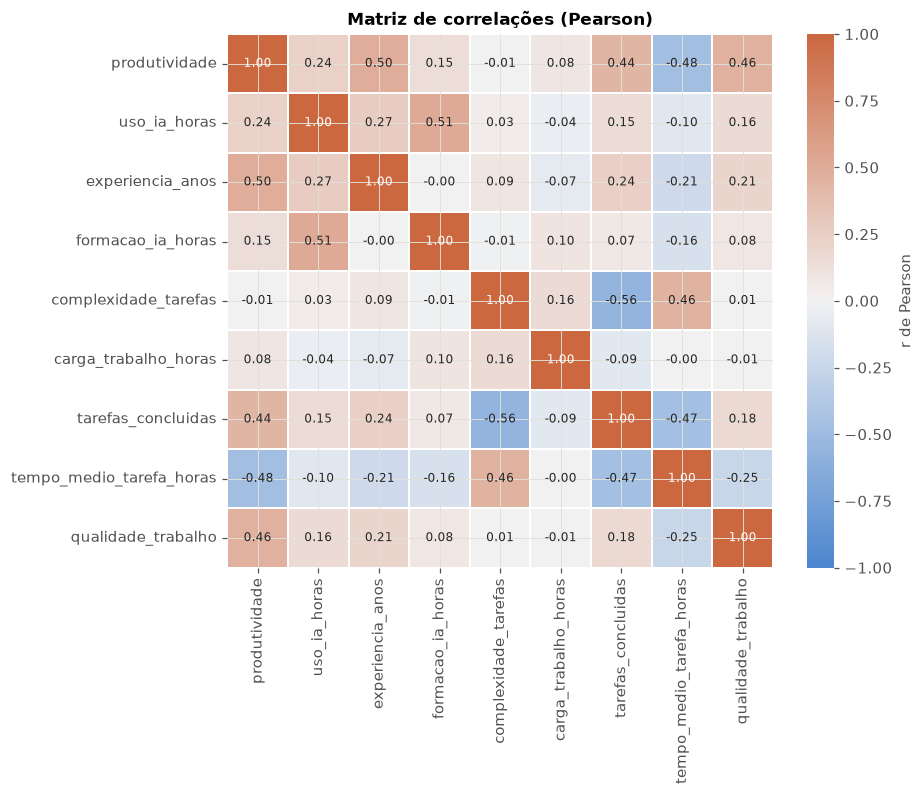

In [ ]:
vars_num = ["produtividade", "uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas",
            "carga_trabalho_horas", "tarefas_concluidas", "tempo_medio_tarefa_horas", "qualidade_trabalho"]
corr = df[vars_num].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6.3))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 25, s=75, l=55, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=1, linecolor="white", ax=ax,
            cbar_kws={"label": "r de Pearson"}, annot_kws={"size": 8})
ax.set_title("Matriz de correlações (Pearson)")
guardar(fig, "fig_6_1_correlacoes"); plt.show()

Variáveis candidatas, lidas a partir da matriz de correlações:

| Variável | r com produtividade | Papel | Decisão |
|---|---|---|---|
| `experiencia_anos` | 0,50 | Característica anterior ao desempenho; correlacionada também com o uso de IA (0,27), logo potencial fator de confusão | Incluir |
| `formacao_ia_horas` | 0,15 | Fator anterior; muito ligado ao uso de IA (0,51) | Incluir |
| `complexidade_tarefas` | −0,01 | Característica do posto de trabalho, referida no enunciado; condiciona o que é possível produzir | Incluir (controlo) |
| `carga_trabalho_horas` | 0,08 | Contexto; associação fraca | Teste de robustez |
| `departamento` | ANOVA p = 0,70 | Contexto | Teste de robustez |
| `tarefas_concluidas` | 0,44 | Indicador do próprio desempenho | Excluir |
| `tempo_medio_tarefa_horas` | −0,48 | Indicador do próprio desempenho | Excluir |
| `qualidade_trabalho` | 0,46 | Indicador do próprio desempenho | Excluir |

Tarefas concluídas, tempo por tarefa e qualidade são resultados do trabalho, provavelmente componentes da própria medida de produtividade ou consequências do mesmo processo. Incluí-las teria três problemas. Primeiro, circularidade: explicar a produtividade com partes dela própria inflaciona o R² sem acrescentar conhecimento. Segundo, se a IA melhorar a produtividade através de mais tarefas concluídas ou de menos tempo por tarefa, controlar esses indicadores apagaria precisamente o efeito que queremos estudar. Terceiro, não são variáveis sobre as quais a direção possa decidir à partida. Por isso deixámo-las de fora.

### 6.2. Modelo múltiplo

In [ ]:
vars_m2 = ["produtividade", "uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas"]
d6 = df.dropna(subset=vars_m2).copy()
print("n (casos completos) =", len(d6))
m2 = smf.ols("produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas + complexidade_tarefas",
             data=d6).fit()
print(m2.summary(slim=True))

n (casos completos) = 233
                            OLS Regression Results                            
Dep. Variable:          produtividade   R-squared:                       0.280
Model:                            OLS   Adj. R-squared:                  0.267
No. Observations:                 233   F-statistic:                     22.14
Covariance Type:            nonrobust   Prob (F-statistic):           1.85e-15
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               67.3227      2.604     25.857      0.000      62.192      72.453
uso_ia_horas             0.1293      0.179      0.722      0.471      -0.224       0.482
experiencia_anos         1.5838      0.190      8.316      0.000       1.209       1.959
formacao_ia_horas        0.2308      0.122      1.896      0.059      -0.009       0.471
complexidade_tarefas    -0.6613      0.716   

O modelo inclui o uso de IA (variável de interesse) e três variáveis que escolhemos porque: (1) são anteriores ao desempenho medido e não fazem parte dele, o que evita a circularidade discutida em 6.1; (2) são os fatores apontados no enunciado como possíveis influências (experiência, formação, complexidade das tarefas); (3) no caso da experiência e da formação, estão associadas ao mesmo tempo ao uso de IA e à produtividade, pelo que são as candidatas naturais a fatores de confusão, cuja omissão enviesa o coeficiente da IA.

Modelo: produtividade = β₀ + β₁·uso_IA + β₂·experiência + β₃·formação_IA + β₄·complexidade + ε, estimado por mínimos quadrados com **n = 233** casos completos. O modelo é globalmente significativo (F(4, 228) = 22,1; p < 0,001).

### 6.3. Equação e interpretação do coeficiente da IA

In [ ]:
coef = pd.DataFrame({"coef": m2.params, "erro-padrão": m2.bse, "t": m2.tvalues, "p": m2.pvalues,
                     "IC95% inf": m2.conf_int()[0], "IC95% sup": m2.conf_int()[1]})
display(coef.round(4))

,coef,erro-padrão,t,p,IC95% inf,IC95% sup
Intercept,67.323,2.604,25.857,0.000,62.192,72.453
uso_ia_horas,0.129,0.179,0.722,0.471,-0.224,0.482
experiencia_anos,1.584,0.190,8.316,0.000,1.209,1.959
formacao_ia_horas,0.231,0.122,1.896,0.059,-0.009,0.471
complexidade_tarefas,-0.661,0.716,-0.923,0.357,-2.073,0.750


$$\widehat{\text{produtividade}} = 67{,}32 + 0{,}129\,\text{uso\_IA} + 1{,}584\,\text{experiência} + 0{,}231\,\text{formação\_IA} - 0{,}661\,\text{complexidade}$$

**Coeficiente do uso de IA (0,129; IC 95%: −0,22 a 0,48; p = 0,47).** Entre colaboradores com a mesma experiência, a mesma formação em IA e a mesma complexidade de tarefas, cada hora semanal adicional de uso de IA está associada a uma produtividade média apenas 0,13 pontos mais alta, um valor pequeno e não estatisticamente diferente de zero. O intervalo de confiança inclui o zero e valores negativos: os dados são compatíveis com a ausência de associação, depois de descontados os outros fatores.

Restantes coeficientes:
- Experiência (1,58; p < 0,001): cada ano adicional de experiência associa-se a mais 1,6 pontos de produtividade, mantendo o resto constante. É o único preditor claramente significativo.
- Formação em IA (0,23; p = 0,059): associação positiva, no limiar da significância; 10 h de formação correspondem a cerca de 2,3 pontos.
- Complexidade (−0,66; p = 0,36): sem associação significativa.
- Ordenada (67,3): corresponde a 0 anos, 0 h de IA, 0 h de formação e complexidade 0, uma combinação fora do domínio (a complexidade mínima é 1), por isso não tem interpretação prática.

Não ordenamos a importância das variáveis pelo valor absoluto dos coeficientes, porque as unidades são diferentes (anos, horas por semana, horas de formação, níveis de 1 a 5).

### 6.4. Alteração do coeficiente da IA

,b_IA,IC inf,IC sup,p,R² aj.
M1: só IA,0.639,0.313,0.965,0.000,0.056
+ formação,0.597,0.216,0.977,0.002,0.053
+ experiência,0.309,0.009,0.610,0.044,0.259
+ experiência + formação,0.128,-0.225,0.481,0.476,0.268
M2: + complexidade,0.129,-0.224,0.482,0.471,0.267


Redução do coeficiente da IA: 80%


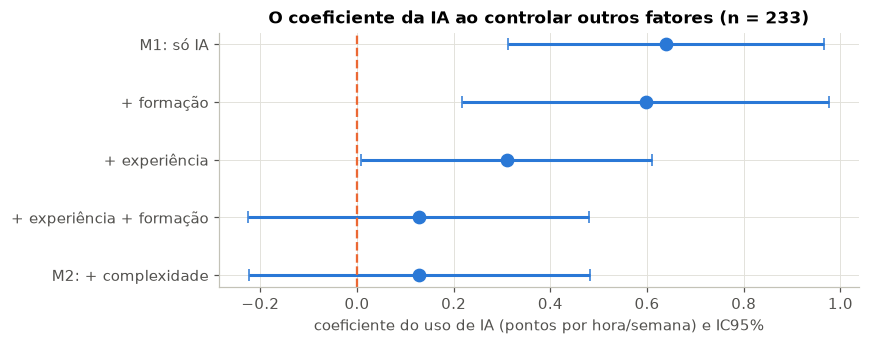

In [ ]:
m1_233 = smf.ols("produtividade ~ uso_ia_horas", data=d6).fit()   # modelo 1 com os mesmos 233 casos
passos = {
    "M1: só IA": "produtividade ~ uso_ia_horas",
    "+ formação": "produtividade ~ uso_ia_horas + formacao_ia_horas",
    "+ experiência": "produtividade ~ uso_ia_horas + experiencia_anos",
    "+ experiência + formação": "produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas",
    "M2: + complexidade": "produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas + complexidade_tarefas",
}
evol = pd.DataFrame({k: (lambda f: pd.Series({"b_IA": f.params["uso_ia_horas"],
                                               "IC inf": f.conf_int().loc["uso_ia_horas", 0],
                                               "IC sup": f.conf_int().loc["uso_ia_horas", 1],
                                               "p": f.pvalues["uso_ia_horas"], "R² aj.": f.rsquared_adj}))
                     (smf.ols(v, d6).fit()) for k, v in passos.items()}).T
display(evol.round(3))
print(f"Redução do coeficiente da IA: {100 * (1 - m2.params['uso_ia_horas'] / m1_233.params['uso_ia_horas']):.0f}%")

fig, ax = plt.subplots(figsize=(7.5, 3))
yy = np.arange(len(evol))[::-1]
ax.errorbar(evol["b_IA"], yy, xerr=[evol["b_IA"] - evol["IC inf"], evol["IC sup"] - evol["b_IA"]],
            fmt="o", color=AZUL, ecolor=AZUL, capsize=4, markersize=8, lw=2)
ax.axvline(0, color=LARANJA, lw=1.5, ls="--")
ax.set_yticks(yy, evol.index); ax.set_xlabel("coeficiente do uso de IA (pontos por hora/semana) e IC95%")
ax.set_title("O coeficiente da IA ao controlar outros fatores (n = 233)")
guardar(fig, "fig_6_4_coeficiente_ia"); plt.show()

O coeficiente da IA passa de **0,639** (modelo simples, mesmos 233 casos; p < 0,001) para **0,129** (modelo múltiplo; p = 0,47). É uma redução de cerca de 80%, e o coeficiente deixa de ser estatisticamente significativo.

A tabela mostra quem "absorve" a associação. Acrescentar só a formação quase não mexe no coeficiente (0,60); acrescentar a experiência reduz-o para metade (0,31; p = 0,04); com experiência e formação em conjunto cai para 0,13. A explicação está na matriz de correlações de 6.1: os colaboradores mais experientes e mais formados usam mais IA (r = 0,27 e 0,51 com o uso de IA) e a experiência está fortemente ligada à produtividade (r = 0,50). Ou seja, quem usa mais IA é mais produtivo, mas em grande parte por ser mais experiente, e não por usar mais IA. É o padrão clássico de uma variável omitida e é este o "paradoxo" do título.

Uma reserva: se a formação levar a mais uso de IA e este a mais produtividade, controlar a formação pode estar a retirar à IA parte de um efeito real. Mesmo assim, controlando apenas a experiência, que não é consequência de usar IA, o coeficiente já cai para metade.

### 6.5. Comparação da capacidade explicativa

In [ ]:
comp = pd.DataFrame({
    "M1 (só IA)": [m1_233.nobs, m1_233.df_model, m1_233.rsquared, m1_233.rsquared_adj, m1_233.fvalue, m1_233.f_pvalue],
    "M2 (IA + 3 variáveis)": [m2.nobs, m2.df_model, m2.rsquared, m2.rsquared_adj, m2.fvalue, m2.f_pvalue],
}, index=["n", "nº preditores", "R²", "R² ajustado", "F global", "p (F global)"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(comp)

,M1 (só IA),M2 (IA + 3 variáveis)
n,233.0000,233.0000
nº preditores,1.0000,4.0000
R²,0.0605,0.2798
R² ajustado,0.0565,0.2672
F global,14.8822,22.1441
p (F global),0.0001,0.0000


A comparação é feita com as mesmas 233 observações (o M1 foi reestimado), senão os R² não seriam comparáveis.

O R² sobe de 0,061 para 0,280. Como o R² nunca desce quando se acrescentam variáveis, olhamos sobretudo para o **R² ajustado**, que penaliza o número de preditores: passa de **0,056 para 0,267**, quase cinco vezes mais. Os dois modelos são globalmente significativos (F(1, 231) = 14,9 e F(4, 228) = 22,1; p < 0,001 em ambos). Com 233 observações para 4 preditores, cerca de 58 por preditor, o ganho não se explica pela complexidade adicional.

Sim, o modelo com mais variáveis apresenta uma melhoria relevante. Ainda assim, cerca de 73% da variabilidade continua por explicar.

### 6.6. Associação entre variáveis explicativas e comportamento dos resíduos

Correlações entre as variáveis explicativas:


,uso_ia_horas,experiencia_anos,formacao_ia_horas,complexidade_tarefas
uso_ia_horas,1.000,0.270,0.510,0.030
experiencia_anos,0.270,1.000,-0.000,0.100
formacao_ia_horas,0.510,-0.000,1.000,-0.010
complexidade_tarefas,0.030,0.100,-0.010,1.000


,Variável,VIF
1,uso_ia_horas,1.510
2,experiencia_anos,1.120
3,formacao_ia_horas,1.400
4,complexidade_tarefas,1.010


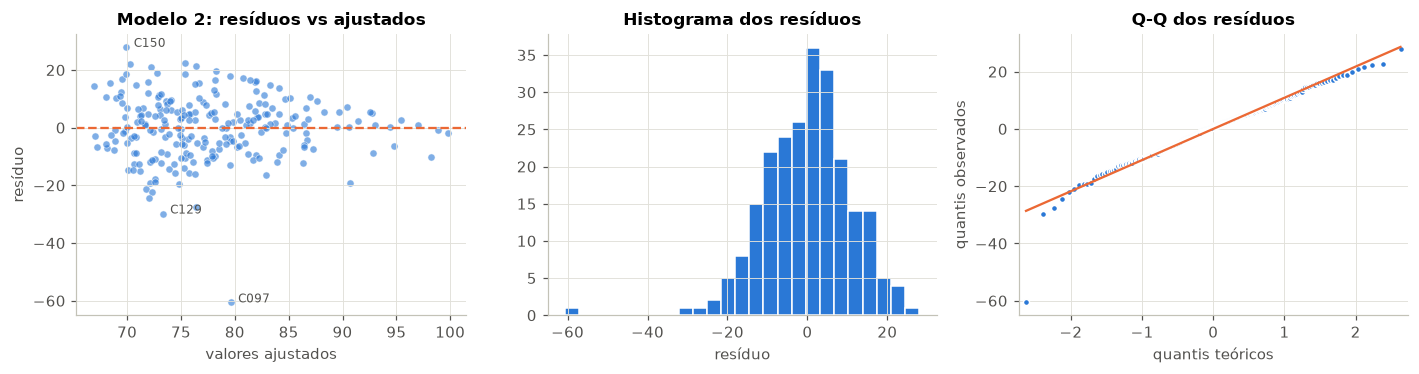

Shapiro-Wilk (normalidade dos resíduos): W = 0.966, p = 2.1e-05
Breusch-Pagan (variância constante): LM = 6.19, p = 0.185
Resíduos: mínimo = -60.6, máximo = 28.0
Observações com maior resíduo em valor absoluto:


,id_colaborador,uso_ia_horas,experiencia_anos,produtividade,ajustado,residuo
96,C097,7.700,7.200,19.000,79.600,-60.600
128,C129,11.500,3.400,43.500,73.290,-29.790
149,C150,2.100,1.600,97.900,69.910,27.990


In [ ]:
preditores = ["uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas"]
print("Correlações entre as variáveis explicativas:")
display(d6[preditores].corr().round(2))
X = m2.model.exog
vif = pd.DataFrame({"Variável": m2.model.exog_names,
                    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]})
display(vif.loc[vif["Variável"] != "Intercept"].round(2))
diagnostico(m2, d6, "Modelo 2", "fig_6_6_residuos_m2")

In [ ]:
# Robustez: (a) sem C097; (b) acrescentando carga de trabalho e departamento
m2_s = smf.ols(m2.model.formula, d6[d6.id_colaborador != "C097"]).fit()
m2_ext = smf.ols(m2.model.formula + " + carga_trabalho_horas + C(departamento)", d6).fit()
rob = pd.DataFrame({
    "M2": [m2.params["uso_ia_horas"], m2.pvalues["uso_ia_horas"], m2.rsquared_adj],
    "M2 sem C097": [m2_s.params["uso_ia_horas"], m2_s.pvalues["uso_ia_horas"], m2_s.rsquared_adj],
    "M2 + carga + departamento": [m2_ext.params["uso_ia_horas"], m2_ext.pvalues["uso_ia_horas"], m2_ext.rsquared_adj],
}, index=["b_IA", "p (IA)", "R² aj."]).T
display(rob.round(3))
print(f"Sem C097: Shapiro-Wilk dos resíduos p = {st.shapiro(m2_s.resid).pvalue:.3f}")

,b_IA,p (IA),R² aj.
M2,0.129,0.471,0.267
M2 sem C097,0.146,0.384,0.302
M2 + carga + departamento,0.144,0.446,0.274


Sem C097: Shapiro-Wilk dos resíduos p = 0.965


**Associação entre as explicativas.** A correlação mais alta entre preditores é entre uso de IA e formação (0,51), moderada; as restantes são fracas. Todos os VIF são inferiores a 1,6 (o máximo é 1,51, no uso de IA), muito abaixo do limiar de 5 referido nas aulas. Não há multicolinearidade problemática: o erro-padrão do coeficiente da IA quase não muda do modelo simples (0,165) para o múltiplo (0,179). A perda de significância da IA não vem de colinearidade; vem de o modelo passar a descontar a experiência.

**Resíduos do modelo 2.**
- Forma da relação: sem curvatura nem padrão nos resíduos contra os valores ajustados.
- Variância constante: Breusch-Pagan p = 0,19, não rejeitada.
- Independência: assumida pelo desenho, como no modelo 1.
- Normalidade: rejeitada (Shapiro-Wilk p < 0,001), mas quase só por causa de C097, que tem um resíduo de −60,6, muito afastado dos restantes. Sem C097 os resíduos são compatíveis com a normalidade (p = 0,97) e o coeficiente da IA praticamente não muda (0,146; p = 0,38).
- Acrescentar carga de trabalho e departamento também não altera a conclusão (0,144; p = 0,45).

Em resumo, o modelo 2 cumpre razoavelmente os pressupostos e a conclusão sobre a IA não depende das opções tomadas.

### 6.7. Modelo mais adequado

Consideramos o **modelo 2 (múltiplo)** o mais adequado para responder à questão de investigação:
1. A questão pergunta como se altera a relação quando se consideram outros fatores, e só o modelo múltiplo permite responder a isso.
2. Explica quase cinco vezes mais variabilidade (R² ajustado 0,27 contra 0,06), com o mesmo número de observações.
3. O modelo simples atribui à IA uma associação que pertence, em grande parte, à experiência; vimos em 5.6 que os seus resíduos se correlacionam 0,45 com a experiência.
4. É simples (4 preditores, VIF baixos), usa apenas fatores anteriores ao desempenho e cumpre razoavelmente os pressupostos.

O modelo 1 continua útil como descrição da associação bruta, mas não como explicação.

---
## 7. Conclusão da investigação

In [ ]:
sintese = pd.DataFrame({
    "Resultado": ["Correlação IA–produtividade (Pearson, n = 236)", "b_IA no modelo simples (n = 233)",
                  "b_IA no modelo múltiplo (n = 233)", "R² aj. modelo simples", "R² aj. modelo múltiplo",
                  "ANOVA departamentos (p)"],
    "Valor": [f"r = {r_p.statistic:.2f} (p < 0,001)",
              f"{m1_233.params['uso_ia_horas']:.3f} (p < 0,001)",
              f"{m2.params['uso_ia_horas']:.3f} (p = {m2.pvalues['uso_ia_horas']:.2f})",
              f"{m1_233.rsquared_adj:.3f}", f"{m2.rsquared_adj:.3f}", f"{anova.pvalue:.2f}"],
})
display(sintese)

,Resultado,Valor
0,"Correlação IA–produtividade (Pearson, n = 236)","r = 0.24 (p < 0,001)"
1,b_IA no modelo simples (n = 233),"0.639 (p < 0,001)"
2,b_IA no modelo múltiplo (n = 233),0.129 (p = 0.47)
3,R² aj. modelo simples,0.056
4,R² aj. modelo múltiplo,0.267
5,ANOVA departamentos (p),0.70


### 7.1. Quem usa mais IA é mais produtivo?
Descritivamente sim, mas pouco. Existe uma associação positiva, fraca e estatisticamente significativa (r = 0,24; ρ = 0,27; p < 0,001): no quarto quartil de uso de IA a produtividade mediana é 84,9, contra 73,0 no primeiro. Contudo, o uso de IA explica só cerca de 6% da variabilidade e há muitos contraexemplos (C134, com 25 h, tem 71,6; C014, com 4,9 h, tem 98). A afirmação da direção é verdadeira como tendência média, mas enganadora como regra individual.

### 7.2. A relação mantém-se quando se consideram outros fatores?
Não. Controlando experiência, formação em IA e complexidade, o coeficiente da IA cai cerca de 80% (de 0,64 para 0,13) e deixa de ser significativo (p = 0,47; IC 95%: −0,22 a 0,48). O principal fator associado à produtividade é a experiência (mais 1,6 pontos por ano; p < 0,001). O resultado mantém-se sem C097 e com carga de trabalho e departamento no modelo.

### 7.3. Resultado mais inesperado
O mais inesperado foi o desaparecimento quase total da associação da IA ao controlar outros fatores, quando a associação bruta era claramente significativa. A evidência: b_IA = 0,639 (p < 0,001) no modelo simples contra 0,129 (p = 0,47) no múltiplo, com os mesmos 233 colaboradores; os VIF baixos (< 1,6) excluem a multicolinearidade como explicação. A associação inicial era em grande parte um reflexo da experiência: os mais experientes usam mais IA (r = 0,27) e são mais produtivos (r = 0,50). Também nos surpreendeu que o colaborador que mais usa IA (C134) esteja abaixo da média e que os departamentos não difiram (p = 0,70), apesar de Desenvolvimento usar visivelmente mais IA.

### 7.4. Limitações
1. Desenho observacional e transversal. Há uma única medição, sem atribuição aleatória do uso de IA, o que não permite inferir causalidade nem excluir causalidade inversa ou fatores de confusão não medidos (motivação, competência digital, tipo de tarefa, qualidade da ferramenta de IA).
2. Qualidade e medição dos dados. Os dados são sintéticos; a produtividade é um índice cuja construção desconhecemos (provavelmente ligado a tarefas, tempo e qualidade); há efeitos de teto e de chão (13 colaboradores em 98, 34 com tempo mínimo de 0,40 h) que comprimem a variabilidade no topo; existe um valor suspeito (C097 = 19); e o uso de IA mede quantidade (horas), não a qualidade ou adequação do uso.

Além disso, o modelo final deixa cerca de 73% da variabilidade por explicar e a complexidade, que é ordinal, foi tratada como numérica.

### 7.5. Recomendação: tornar obrigatória a utilização de IA?
Não recomendaríamos tornar a IA obrigatória com base nestes resultados.
- A evidência é de associação, não de causalidade. A associação bruta é fraca e desaparece quando comparamos colaboradores com a mesma experiência e formação. Não há, portanto, evidência de que mais horas de IA produzam mais produtividade.
- Mesmo que existisse um efeito, o modelo simples sugere no máximo cerca de 0,6 pontos por hora: impor mais 5 h por semana teria um ganho esperado de 3 pontos, no máximo, com custos (tempo, licenças, resistência à mudança) que não avaliámos.
- A experiência é o fator mais associado à produtividade; a formação em IA tem uma associação positiva marginal (p ≈ 0,06). Uma obrigação uniforme ignora que o efeito pode depender do tipo de tarefa e da competência de cada colaborador.

Em alternativa: manter a IA disponível e opcional; investir em formação de qualidade; para avaliar o efeito causal, realizar um estudo piloto controlado (por exemplo, atribuir aleatoriamente acesso e formação a equipas comparáveis e medir a produtividade antes e depois); e melhorar a medição, com uma produtividade sem teto e um registo do tipo e da qualidade do uso de IA.

Respondendo à questão central: nestes dados, quem usa mais IA é ligeiramente mais produtivo, mas essa vantagem explica-se sobretudo por serem colaboradores mais experientes e formados. Trabalhar com IA não significa, por si só, trabalhar melhor.

---
### Referências
- Coelho, L. (2026). *Modelos Estatísticos para Inteligência Artificial*, Aulas 1 a 5 e guia de testes paramétricos e não paramétricos (material de apoio da UC). Mestrado em Inteligência Artificial, IPCA.
- Montgomery, D. C., Peck, E. A., & Vining, G. G. (2021). *Introduction to Linear Regression Analysis* (6.ª ed.). Wiley.
- Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proc. 9th Python in Science Conference*.
- Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.